# 5.2 Sampling Concepts

**Goal:** separate random sampling error from bias and use resampling at the correct observational unit.

**Prerequisites:** Modules 0–4 and earlier notebooks in this module; advanced notebooks also build on earlier modules 5–8. Read the section assumptions before using a method.

**Runtime:** Python 3.10+ with NumPy, SciPy, and Matplotlib. Install in your chosen environment with `python3 -m pip install numpy scipy matplotlib`, then open in JupyterLab or VS Code with a Python kernel. Use **Restart Kernel and Run All**. Each notebook is self-contained, includes saved outputs, uses synthetic data and a fixed local random seed, and needs no downloads. Numerical simulations illustrate results; they do not prove them or validate real-world assumptions.

## Module navigation

1. [Sampling Techniques](1_Sampling-Techniques.ipynb)
2. [Sampling Concepts](2_Sampling-Concepts.ipynb)
3. [Estimation Theory](3_Estimation-Theory.ipynb)
4. [Confidence Intervals](4_Confidence-Intervals.ipynb)
5. [Hypothesis Testing](5_Hypothesis-Testing.ipynb)
6. [Statistical Errors](6_Statistical-Errors.ipynb)
7. [Statistical Tests](7_Statistical-Tests.ipynb)

## Learning route

Read each definition and assumption, work through its calculation, run the code, then attempt the practice before viewing the solutions. Distinguish descriptive association, causal inference, and predictive evaluation throughout.

In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats, optimize, special, linalg
rng = np.random.default_rng(2026)
plt.rcParams.update({"figure.figsize": (7, 4), "axes.titlesize": 12, "font.size": 10})

## 1. Sampling Distribution and Standard Error

A sampling distribution describes a statistic over repetitions of a specified design. The standard error is its standard deviation. For IID observations with finite variance, $SE(\bar X)=\sigma/\sqrt n$; estimate it with s/√n when appropriate. SD describes individual values, not uncertainty of their mean.

**Worked example:** observations with SD 10 and n=25 give SE 2 under IID sampling. If all observations are exact repeats of one measurement, that formula is invalid. Increasing repetitions of a simulation improves numerical estimation of a sampling distribution; increasing the original sample size changes that distribution itself.

In [2]:
x=np.array([8.,9.,10.,12.,16.,18.,19.,21.])
print("SD:",x.std(ddof=1),"IID mean SE estimate:",x.std(ddof=1)/np.sqrt(len(x)))

SD: 4.998213966722799 IID mean SE estimate: 1.767135494845502


## 2. Sample Size, Sampling Error, and Sampling Bias

Sampling error is random discrepancy between a statistic and its target from selecting a sample; **sampling bias** is systematic distortion from selection or the estimation procedure. Sample size reduces typical random error under suitable assumptions, not systematic bias. For a mean with known design-relevant SD, normal-approximation planning gives $n\approx(z_{1-\alpha/2}\sigma/E)^2$ for target margin E, rounded upward. This requires a credible scale estimate and design assumptions, and differs from power planning for a test.

**Non-response bias** arises when response depends on relevant characteristics. Compare invitation and response rates across groups; weighting can help only with defensible response assumptions and measured predictors. Missing-not-at-random mechanisms can remain unidentified from observed data alone.

**Example:** 1000 invitations produce 100 responses exclusively from heavy users. A small computed SE about their mean does not justify generalization to all users.

In [3]:
z=stats.norm.ppf(.975); target_margin=2; assumed_sd=10
print("Approximate IID n for mean margin 2:",math.ceil((z*assumed_sd/target_margin)**2))
print("Group response rates:",{"low_use":20/200,"high_use":160/200})

Approximate IID n for mean margin 2: 97
Group response rates: {'low_use': 0.1, 'high_use': 0.8}


## 3. Bootstrap Sampling

The nonparametric bootstrap samples n observations **with replacement** from the empirical sample, repeats the statistic, and uses the replicate distribution to estimate sampling variability. Bootstrap SE is the SD of replicate statistics. A simple percentile interval takes bootstrap quantiles; it is an approximation, not automatically exact or reliable for every statistic.

Assumptions include a suitable independent sampling unit and a statistic/distribution regime where resampling is valid. Use a cluster bootstrap for clustered units or an appropriate block bootstrap for dependent sequences. Ordinary bootstrap can fail with tiny samples, extremes, boundary estimates, rare classes, or unobserved population subgroups. More bootstrap replicates reduce Monte Carlo noise but cannot fix an unrepresentative original sample.

**Example:** bootstrap an eight-value mean and compare its SE with the analytic IID estimate. Their values need not match exactly; the empirical distribution and finite-sample denominator conventions differ.

Bootstrap mean SE: 1.6653458407766601
Percentile interval: [11.    17.375]


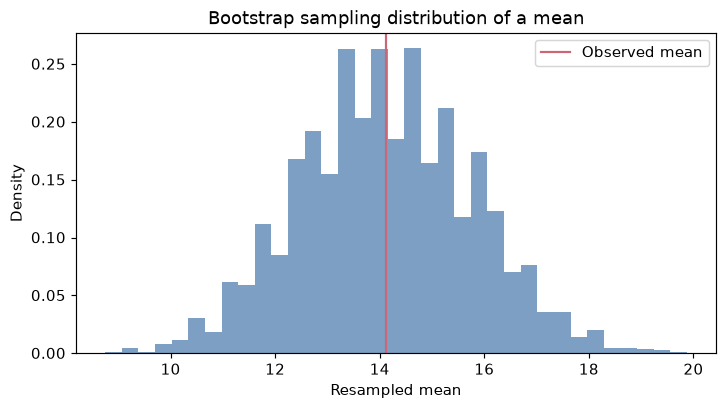

In [4]:
B=6000
bootstrap_means=rng.choice(x,size=(B,len(x)),replace=True).mean(axis=1)
print("Bootstrap mean SE:",bootstrap_means.std(ddof=1))
print("Percentile interval:",np.quantile(bootstrap_means,[.025,.975]))
fig,ax=plt.subplots()
ax.hist(bootstrap_means,bins=35,density=True,color="#4477AA",alpha=.7)
ax.axvline(x.mean(),color="#CC6677",label="Observed mean")
ax.set(title="Bootstrap sampling distribution of a mean",xlabel="Resampled mean",ylabel="Density")
ax.legend();fig.tight_layout();plt.show()

## 4. Jackknife Resampling

The delete-one jackknife recomputes a statistic after omitting each of n observations. Let $\hat\theta_{(-i)}$ be these estimates and their mean be $\bar\theta_{(-)}$. Jackknife SE is
$$\sqrt{\frac{n-1}{n}\sum_i(\hat\theta_{(-i)}-\bar\theta_{(-)})^2}.$$
Estimated bias is $(n-1)(\bar\theta_{(-)}-\hat\theta)$; subtracting it gives a bias-corrected estimate. Smooth statistics such as means are suitable introductory cases. Nonsmooth statistics such as medians or extreme quantiles may behave poorly, so the method is not universally interchangeable with bootstrap.

**Worked example:** for the sample mean, the jackknife SE equals s/√n. Deleting influential points also gives a sensitivity view, but a large leave-one-out change is not proof the point is invalid.

In [5]:
leave_one=np.array([np.delete(x,i).mean() for i in range(len(x))])
jack_se=np.sqrt((len(x)-1)/len(x)*np.sum((leave_one-leave_one.mean())**2))
bias=(len(x)-1)*(leave_one.mean()-x.mean())
print("Jackknife SE:",jack_se,"estimated mean bias:",bias)
assert np.isclose(jack_se,x.std(ddof=1)/np.sqrt(len(x)))

Jackknife SE: 1.767135494845502 estimated mean bias: 0.0


## AI/ML application and interpretation

For model comparison on the same independent test cases, bootstrap the paired per-case outcomes rather than resampling each model separately. Resampling cross-validation fold scores as independent observations is generally unjustified because training sets overlap. State whether uncertainty covers only a fixed model on new cases or also retraining variability.

## Practice

1. How does SE change when IID sample size increases from 25 to 100 with unchanged population SD?
2. Does a bootstrap with a million replicates eliminate selection bias?
3. Distinguish non-response from sampling error.
4. What is the sampling unit for a bootstrap of repeated visits nested within patients?
5. Why might delete-one jackknife be unreliable for a sample maximum?

## Solutions

1. It halves because SE is proportional to 1/√n under these conditions.
2. No. It reduces simulation error in an approximation based on the same observed empirical distribution.
3. Non-response can systematically change the observed population; sampling error is random fluctuation under the design.
4. Often the patient, resampling whole patient records, if patients are the independent units and inference targets that design.
5. The maximum is nonsmooth: deleting most points changes nothing and deleting the largest causes a discontinuous change. Standard jackknife theory need not apply.

**Readiness check:** identify the estimand, independent unit, assumptions, uncertainty source, and an important failure mode before using these methods.

**Next:** [Continue studying](3_Estimation-Theory.ipynb).